# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Іванів Христина'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 4      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 4, файл lr6_варіант_04.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'
# чому: цільова змінна «відтік» бінарна (0/1), а модель має оцінювати ймовірність розриву договору.

METRIC = 'AUC'
# чому саме ця, а не точність: частка відтоку ≈ 27 %, тому модель «ніхто не піде» мала б
# точність ≈ 73 % за нульової користі; AUC не залежить від порогу й оцінює якість ранжування
# клієнтів за ризиком, а саме за ним відділ утримання добиратиме, кому телефонувати.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку відтоку в кожній згортці; 4 повтори дають 20 оцінок
# замість 5, тож розкид і довірчий інтервал оцінюються надійніше на вибірці лише з 1200 рядків.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.273

типи стовпців: {'str': 13, 'float64': 8, 'int64': 5}


In [6]:
# таблиця «стовпець | тип | унікальних | % пропусків | приклад»
overview = pd.DataFrame({
    'стовпець':    raw.columns,
    'тип':         raw.dtypes.astype(str).values,
    'унікальних':  raw.nunique().values,
    '% пропусків': (raw.isna().mean() * 100).round(1).values,
    'приклад':     [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)
display(overview)

n_obj = int(raw.dtypes.astype(str).isin(['object', 'str', 'string']).sum())
top = overview.iloc[0]
print('рядків: %d, стовпців: %d' % raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print('стовпців із текстовим (невизначеним) типом: %d' % n_obj)
print('найбільше пропусків: %s (%.1f %%)' % (top['стовпець'], top['% пропусків']))

,стовпець,тип,унікальних,% пропусків,приклад
0,код_причини_закриття,str,5,72.8,ПЕР-01
1,сума_повернення_депозиту,float64,325,72.8,304.26
2,середній_час_відповіді_хв,float64,265,33.3,1.0
3,трафік_ГБ,str,962,5.0,50.9
4,щомісячний_платіж,str,1127,4.0,315.85
5,аварій_на_ділянці_за_квартал,float64,5,3.0,0.0
6,id_клієнта,str,1200,0.0,K40000
7,оцінка_ризику_менеджером,float64,5,0.0,3.0
8,дата_підключення,str,597,0.0,2024-12-21
9,скоринг_партнера,float64,1199,0.0,832.336


рядків: 1200, стовпців: 26
частка відтоку: 0.273
стовпців із текстовим (невизначеним) типом: 13
найбільше пропусків: код_причини_закриття (72.8 %)


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# 1) текст у числовій колонці: значення, які не розбираються як число
for c in ['щомісячний_платіж', 'трафік_ГБ']:
    s = raw[c].dropna().astype(str)
    bad = s[~s.str.fullmatch(r'-?\d+(\.\d+)?')]
    print('%-20s нечислових значень: %3d   приклади: %s' % (c, len(bad), bad.head(6).tolist()))

# 2) Excel-дата замість числа: рядки виду «1900-01-06 00:00:00»
s = raw['трафік_ГБ'].dropna().astype(str)
print('\nExcel-дати в трафік_ГБ:', s[s.str.match(r'\d{4}-\d\d-\d\d')].tolist())

# 3) MNAR: коли пропущений середній_час_відповіді_хв?
miss = raw['середній_час_відповіді_хв'].isna()
print('\nпропуск часу відповіді за кількістю звернень до підтримки:')
display(pd.crosstab(raw['кількість_звернень_у_підтримку'], miss, rownames=['звернень'], colnames=['пропуск']))

щомісячний_платіж    нечислових значень:  27   приклади: ['205.49 грн', '199.39 грн', '208.14 грн', '263.93 грн', '235.74 грн', '324.0 грн']
трафік_ГБ            нечислових значень:   3   приклади: ['1900-01-06 00:00:00', '1900-01-11 00:00:00', '1900-01-27 00:00:00']

Excel-дати в трафік_ГБ: ['1900-01-06 00:00:00', '1900-01-11 00:00:00', '1900-01-27 00:00:00']

пропуск часу відповіді за кількістю звернень до підтримки:


пропуск,False,True
звернень,,
0,0,400
1,437,0
2,227,0
3,108,0
4,22,0
5,6,0


**Висновок до завдання 2.2.** Знайдено три проблеми: у `щомісячний_платіж` 27 значень записано текстом із «грн»; у `трафік_ГБ` три значення Excel перетворив на дату (`1900-01-06` тощо); у `середній_час_відповіді_хв` пропуски (33,3 %) не випадкові: усі вони припадають на клієнтів із нулем звернень до підтримки (400 з 400), тобто пропуск означає «часу відповіді немає, бо звернень не було» (механізм MNAR). Отже, такі пропуски не слід заповнювати середнім, а сам факт пропуску несе інформацію.

In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'            # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'пропуск означає, що клієнт жодного разу не звертався до підтримки (звернень = 0), тож часу відповіді просто немає'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        # 2) datetime / Timestamp — це брак, а не дані
        if isinstance(v, (datetime.datetime, pd.Timestamp)):
            return np.nan
        # 3) число
        if isinstance(v, (int, float, np.number)):
            return float(v)
        # 4) текст: дата, яку Excel записав рядком, теж брак; інакше — перше число в тексті
        t = str(v).strip()
        if re.match(r'\d{4}-\d{2}-\d{2}', t):
            return np.nan
        m = re.search(r'-?\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        is_text = str(s.dtype) in ('object', 'str', 'string')
        if c == 'дата_підключення':
            # дата -> порядковий номер дня від 01.01.2020
            X[c] = (pd.to_datetime(s) - pd.Timestamp('2020-01-01')).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'дата -> число (день від 2020-01-01)'})
        elif is_text:
            # «числова» текстова колонка: значення має ВИГЛЯДАТИ як число з необов'язковою одиницею
            # («350.5 грн»); просте «є цифра в тексті» хибно спрацювало б на кодах «Ф-03 Схід», «НОМ-035»
            looks_num = s.dropna().astype(str).str.fullmatch(r'\s*-?\d+(?:[.,]\d+)?\s*[^\W\d_]*\.?\s*')
            if looks_num.mean() > 0.8:
                X[c] = to_number(s)
                log.append({'стовпець': c, 'рішення': 'текст -> число (to_number)'})
            else:
                t = s.astype(str).str.strip().str.lower().where(s.notna())
                if c == 'стать':
                    # «ч», «чол», «Ч» — той самий код: лишаємо першу літеру
                    t = t.str[0]
                X[c] = t.astype('category')
                log.append({'стовпець': c, 'рішення': 'категорія (%d рівнів після чищення)' % X[c].nunique()})
        else:
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число (float)'})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення
0,вік,число (float)
1,стать,категорія (2 рівнів після чищення)
2,місто,категорія (6 рівнів після чищення)
3,філія,категорія (6 рівнів після чищення)
4,тариф,категорія (4 рівнів після чищення)
5,тип_підключення,категорія (3 рівнів після чищення)
6,спосіб_оплати,категорія (3 рівнів після чищення)
7,автоплатіж,категорія (2 рівнів після чищення)
8,кількість_послуг,число (float)
9,місяців_обслуговування,число (float)


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.993


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.993 ± 0.003
час      : 0.3 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'AUC 0,993 означає, що ранжування майже ідеальне, тобто клієнтів фактично розділено без помилок; для задачі відтоку реалістичні значення лежать у діапазоні 0,7–0,85, тож із двох причин високої AUC (легка задача або витік) найімовірніше спрацював витік цілі: у вивантаженні є поля, що заповнюються вже після розриву договору.'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0,993 означає, що ранжування майже ідеальне, тобто клієнтів фактично розділено без помилок; для задачі відтоку реалістичні значення лежать у діапазоні 0,7–0,85, тож із двох причин високої AUC (легка задача або витік) найімовірніше спрацював витік цілі: у вивантаженні є поля, що заповнюються вже після розриву договору.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_f, n_e = int(filled.sum()), int((~filled).sum())
        enough = n_f >= min_group and n_e >= min_group
        score = np.nan
        if enough:
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a)          # напрям неважливий: важить сама інформативність
        rows.append({'ознака': c, 'заповнено': n_f,
                     'частка_відтоку_де_заповнено': y[filled].mean() if n_f else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n_e else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,327,1.000000,0.000000,1.000000
23,код_причини_закриття,327,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,800,0.312500,0.192500,0.567257
14,трафік_ГБ,1140,0.273684,0.250000,0.502837
12,щомісячний_платіж,1152,0.271701,0.291667,0.501934
16,аварій_на_ділянці_за_квартал,1164,0.273196,0.250000,0.501702
0,id_клієнта,1200,0.272500,NaN,NaN
1,вік,1200,0.272500,NaN,NaN
2,стать,1200,0.272500,NaN,NaN
3,місто,1200,0.272500,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'сума_повернення_депозиту',   # депозит повертають під час закриття договору — тобто вже після розриву
    'код_причини_закриття',       # причину закриття вказують під час оформлення розірвання, якого ще не було
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.972 ± 0.008


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# перегляд стовпців, що лишились: чи відоме значення в момент звернення клієнта?
print(list(X2.columns))
display(raw[X2.columns].describe(include='all').T[['count', 'unique', 'min', 'max']].fillna(''))
# перевірка підозрюваного: частка відтоку за значенням оцінки менеджера
display(raw.groupby('оцінка_ризику_менеджером')[TARGET].agg(['mean', 'size']).round(3))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


,count,unique,min,max
вік,1200.0,,18.0,85.0
стать,1200,6,,
місто,1200,6,,
філія,1200,6,,
тариф,1200,4,,
тип_підключення,1200,3,,
спосіб_оплати,1200,3,,
автоплатіж,1200,2,,
кількість_послуг,1200.0,,1.0,3.0
місяців_обслуговування,1200.0,,1.0,120.0


,mean,size
оцінка_ризику_менеджером,,
1.0,0.000,237
2.0,0.027,405
3.0,0.222,279
4.0,0.867,188
5.0,1.000,91


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',   # менеджер виставляє її вже знаючи, що клієнт іде: оцінка 1–2 → відтоку майже немає, 4–5 → майже завжди
]
HUMAN_LEAK_WHY = 'поле заповнене в усіх 100 % рядків, тож «заповненість» нічого не розрізняє (показник 0,5); витік міститься у самих значеннях, а не в пропусках'

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.846 ± 0.029


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.394,216
Ф-02 Захід,0.325,200
Ф-05 Північ,0.262,195
Ф-04 Південь,0.241,195
Ф-03 Схід,0.228,189
Ф-06 Приміська,0.176,205


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.292,144
2023Q2,0.308,146
2023Q3,0.303,152
2023Q4,0.230,178
2024Q1,0.264,125
2024Q2,0.269,145
2024Q3,0.316,158
2024Q4,0.204,152


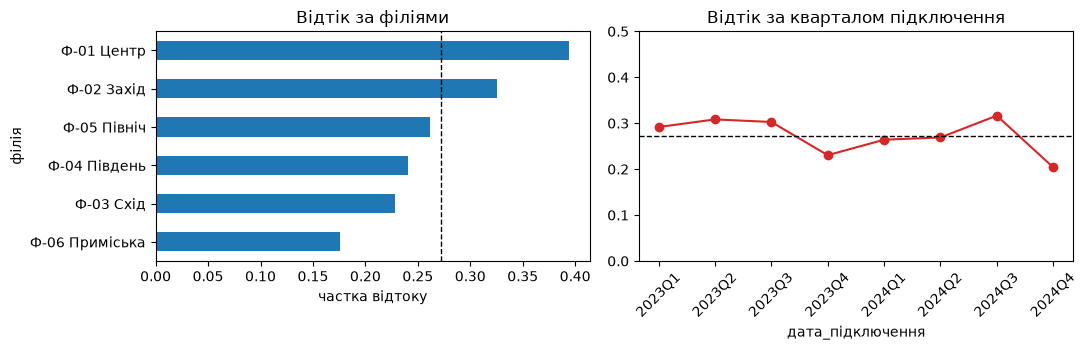

In [19]:
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній)
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3)
by_branch.columns = ['частка відтоку', 'клієнтів']
display(by_branch.sort_values('частка відтоку', ascending=False))

# 2) частка відтоку за кварталами дати підключення
q = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q').astype(str)
by_q = raw.groupby(q)[TARGET].agg(['mean', 'size'])
by_q.columns = ['частка відтоку', 'клієнтів']
display(by_q.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
by_branch['частка відтоку'].sort_values().plot.barh(ax=ax[0], color='tab:blue')
ax[0].axvline(raw[TARGET].mean(), color='k', ls='--', lw=1)
ax[0].set_title('Відтік за філіями'); ax[0].set_xlabel('частка відтоку')
by_q['частка відтоку'].plot(ax=ax[1], marker='o', color='tab:red')
ax[1].axhline(raw[TARGET].mean(), color='k', ls='--', lw=1)
ax[1].set_title('Відтік за кварталом підключення'); ax[1].set_ylim(0, 0.5)
ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме є підозрюваним
assert SUSPECT in ('філія', 'дата_підключення')

# для 'філія': 1 для філій із різко вищою часткою відтоку (≥ 30 %: «Центр» і «Захід»)
rate = raw.groupby('філія')[TARGET].mean()
bad_branches = rate[rate >= 0.30].index.tolist()
print('філії-підозрювані:', bad_branches)
source = raw['філія'].isin(bad_branches).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

# що саме видає джерело: які ознаки найсильніше відрізняють «підозрювані» філії
_m = make_pipe(X4, logreg()).fit(X4, source)
_coef = pd.Series(_m.named_steps['clf'].coef_[0],
                  index=_m.named_steps['prep'].get_feature_names_out())
display(_coef.reindex(_coef.abs().sort_values(ascending=False).index).head(5).to_frame('коефіцієнт'))

філії-підозрювані: ['Ф-01 Центр', 'Ф-02 Захід']


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.692
ті самі ознаки передбачають ВІДТІК  : AUC 0.834 ± 0.031


,коефіцієнт
num__річний_платіж,-1.654211
num__швидкість_тарифу_Мбіт,1.137785
cat__номер_договору_серія_ном-010,-0.996809
cat__номер_договору_серія_ном-046,0.972921
cat__номер_договору_серія_ном-054,-0.840272


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.993
2. мінус цільовий витік,22,0.972
3. мінус оцінки людини,21,0.846
4. мінус артефакт збору,20,0.834


чесне число: 0.834 ± 0.031


**Висновок до драбини.** Перше число (AUC 0,993) обумовлене витоком: відразу після вилучення двох полів, заповнених лише для клієнтів, що пішли, показник майже не змінився (0,972), бо логістична регресія використала ще одне джерело витоку — оцінку менеджера. Її вилучення знизило AUC до 0,846, тобто головний витік знайдено на кроці 3 (−0,126). Вилучення підозрюваної філії додало ще −0,012. Чесне число — AUC 0,834 ± 0,031.

### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'різкої «сходинки» немає: частка відтоку за кварталами підключення коливається в межах 20–32 % без злому, а філії різняться плавно (від 17,6 % до 39,4 %). Проте за чесними ознаками філії «Центр» і «Захід» вгадуються з AUC 0,692, тобто склад клієнтів у них відмінний (зокрема більша частка оптики), і модель могла б вивчити «адресу», а не причину відтоку. Вилучення коштує 0,012 AUC (0,846 → 0,834), що менше за розкид ±0,031, тому надійніше викинути; для нової філії такий стовпець усе одно не мав би сенсу.'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — різкої «сходинки» немає: частка відтоку за кварталами підключення коливається в межах 20–32 % без злому, а філії різняться плавно (від 17,6 % до 39,4 %). Проте за чесними ознаками філії «Центр» і «Захід» вгадуються з AUC 0,692, тобто склад клієнтів у них відмінний (зокрема більша частка оптики), і модель могла б вивчити «адресу», а не причину відтоку. Вилучення коштує 0,012 AUC (0,846 → 0,834), що менше за розкид ±0,031, тому надійніше викинути; для нової філії такий стовпець усе одно не мав би сенсу.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                                   random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                           max_iter=150, random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.834,0.031,0.4
одне дерево,0.766,0.032,0.3
випадковий ліс,0.830,0.031,3.9
гістограмний бустинг,0.832,0.025,5.7


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)          # різниця по кожній згортці
    k = len(d)
    # поправка Надо–Бенжіо: згортки перекриваються, тож дисперсію множимо на (1/k + n_test/n_train);
    # для 5-кратної схеми n_test/n_train = 1/4
    var = d.var(ddof=1) * (1 / k + 1 / 4)
    return d.mean(), stats.t.ppf(0.975, k - 1) * np.sqrt(var)


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0042 ± 0.0266   у межах шуму


гістограмний бустинг   проти логістичної: -0.0021 ± 0.0204   у межах шуму


**Висновок до завдання 7.** Одне дерево помітно слабше (0,766), а логістична регресія, ліс і бустинг (0,834 / 0,830 / 0,832) статистично не розрізняються. Складніші моделі не дають виграшу, бо залежності на чесних ознаках переважно лінійні, а даних лише 1200 рядків.

In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'за точністю всі три сильні моделі рівні в межах шуму (AUC 0,834 проти 0,830 і 0,832; різниця −0,004 ± 0,027 та −0,002 ± 0,020), тож вирішують інші критерії: швидкість (0,4 с на 100 навчань проти 4,1 і 5,7 с), інтерпретованість (коефіцієнти замість лісу) і стабільність (найменша складність за однакової якості).'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — за точністю всі три сильні моделі рівні в межах шуму (AUC 0,834 проти 0,830 і 0,832; різниця −0,004 ± 0,027 та −0,002 ± 0,020), тож вирішують інші критерії: швидкість (0,4 с на 100 навчань проти 4,1 і 5,7 с), інтерпретованість (коефіцієнти замість лісу) і стабільність (найменша складність за однакової якості).


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # гіпотеза 1: переплата — клієнт платить багато за малу швидкість і почувається ошуканим
    F['платіж_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза 2: часті звернення на місяць обслуговування — ознака проблем із послугою
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # гіпотеза 3: клієнт, що майже не користується трафіком за свої гроші, легше йде
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    # гіпотеза 4: новачок (до 6 місяців) ще не прив'язаний до провайдера
    F['новачок'] = (F['місяців_обслуговування'] <= 6).astype(float)
    # гіпотеза 5: аварії на ділянці без жодного звернення — клієнт терпить і може піти мовчки
    F['аварії_без_звернень'] = ((F['аварій_на_ділянці_за_квартал'] > 0)
                                & (F['кількість_звернень_у_підтримку'] == 0)).astype(float)
    F = F.replace([np.inf, -np.inf], np.nan)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 25


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.832 ± 0.032
приріст проти базового набору: -0.0023 ± 0.0055   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Нові ознаки дали −0,0023 ± 0,0055 AUC (у межах шуму) без додаткових витрат часу; складніша модель дала −0,0042 ± 0,0266 (ліс, +3,7 с на 100 навчань) та −0,0021 ± 0,0204 (бустинг, +5,3 с). Жоден шлях не покращив результат: на чесному наборі лінійна залежність уже вичерпана, а єдиний справжній приріст дала ознака, підказана PDP (квадрат відхилення віку, +0,0230 ± 0,0138).'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Нові ознаки дали −0,0023 ± 0,0055 AUC (у межах шуму) без додаткових витрат часу; складніша модель дала −0,0042 ± 0,0266 (ліс, +3,7 с на 100 навчань) та −0,0021 ± 0,0204 (бустинг, +5,3 с). Жоден шлях не покращив результат: на чесному наборі лінійна залежність уже вичерпана, а єдиний справжній приріст дала ознака, підказана PDP (квадрат відхилення віку, +0,0230 ± 0,0138).


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.796
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
вік,0.099935
номер_договору_серія,0.099349
трафік_на_гривню,0.070633
річний_платіж,0.070431
платіж_за_Мбіт,0.063427
щомісячний_платіж,0.062788
місяців_обслуговування,0.057894
трафік_ГБ,0.052794
швидкість_тарифу_Мбіт,0.051090
звернень_на_місяць,0.047974


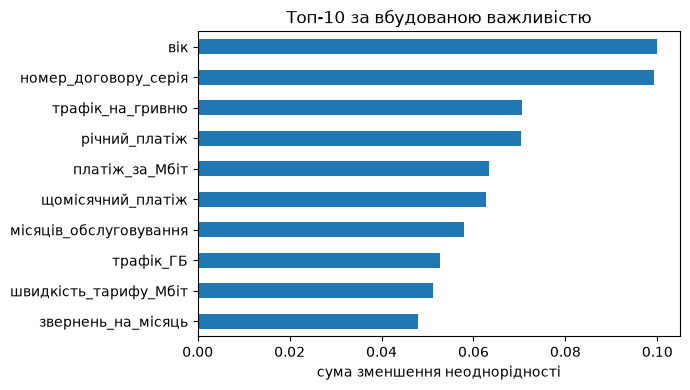

In [30]:
names = model.named_steps['prep'].get_feature_names_out()
raw_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=names)

cat_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']

def origin(n):
    # 'num__вік' -> 'вік'; 'cat__тариф_Базовий' -> 'тариф' (найдовший збіг серед категоріальних)
    base_name = n.split('__', 1)[1]
    if n.startswith('cat__'):
        return max((c for c in cat_cols if base_name.startswith(c + '_')), key=len)
    return base_name

gini_imp = raw_imp.groupby(origin).sum().sort_values(ascending=False)
display(gini_imp.head(10).to_frame('вбудована важливість'))

fig, ax = plt.subplots(figsize=(7, 4))
gini_imp.head(10)[::-1].plot.barh(ax=ax, color='tab:blue')
ax.set_title('Топ-10 за вбудованою важливістю'); ax.set_xlabel('сума зменшення неоднорідності')
plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.068044
місяців_обслуговування,0.035416
звернень_на_місяць,0.022383
річний_платіж,0.007791
щомісячний_платіж,0.007382
швидкість_тарифу_Мбіт,0.007003
автоплатіж,0.006720
трафік_ГБ,0.004498
трафік_на_гривню,0.004494
аварій_на_ділянці_за_квартал,0.003694


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
cmp_imp['ранг_вбудованої'] = range(1, len(cmp_imp) + 1)
cmp_imp['різних значень'] = [FINAL_X[c].nunique() for c in cmp_imp.index]
display(cmp_imp.head(10).round(4))

,вбудована,перестановочна,ранг_вбудованої,різних значень
вік,0.0999,0.0680,1,62
номер_договору_серія,0.0993,0.0017,2,55
трафік_на_гривню,0.0706,0.0045,3,1090
річний_платіж,0.0704,0.0078,4,1171
платіж_за_Мбіт,0.0634,-0.0019,5,1141
щомісячний_платіж,0.0628,0.0074,6,1126
місяців_обслуговування,0.0579,0.0354,7,82
трафік_ГБ,0.0528,0.0045,8,959
швидкість_тарифу_Мбіт,0.0511,0.0070,9,9
звернень_на_місяць,0.0480,0.0224,10,138


**Висновок до завдання 9.3.** Ознака `номер_договору_серія` має другу за величиною вбудовану важливість (0,099) і майже нульову перестановочну (0,0017). Вона має 55 різних значень, тому дерево знаходить для неї багато порогів і переоцінює її. Так само переоцінено `платіж_за_Мбіт` (5-те місце, перестановочна −0,0019).

In [33]:
FAKE_IMPORTANT = 'номер_договору_серія'        # назва ознаки
FAKE_IMPORTANT_WHY = 'це майже ідентифікатор із 55 різних значень: дерево для нього має багато можливих розбиттів і завжди знаходить таке, що трохи зменшує неоднорідність на навчальній вибірці, хоча зв’язку з відтоком немає. Вбудована важливість 0,099 (2-ге місце), а перестановочна на перевірковій частині лише 0,0017.'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: номер_договору_серія


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
corr = FINAL_X.select_dtypes('number').corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename('r').reset_index())
pairs.columns = ['ознака 1', 'ознака 2', 'r']
display(pairs[pairs['r'].abs() > 0.97].sort_values('r', key=abs, ascending=False).round(4))

,ознака 1,ознака 2,r
82,щомісячний_платіж,річний_платіж,0.9993


In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# прибираємо DUP_PAIR[1], навчаємо заново, рахуємо перестановочну важливість
X_nodup = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr_nd, Xte_nd = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])
model_nd = make_pipe(X_nodup, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_nd, ytr)
perm_nd = permutation_importance(model_nd, Xte_nd, yte, n_repeats=10,
                                 random_state=SEED, scoring='roc_auc')
perm_nd_imp = pd.Series(perm_nd.importances_mean, index=X_nodup.columns)
print('без пари (%s прибрано):' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_nd_imp[DUP_PAIR[0]]))
print('   AUC на відкладеній частині: %.3f (було %.3f)' % (
    roc_auc_score(yte, model_nd.predict_proba(Xte_nd)[:, 1]), auc_hold))

у повній моделі:
   щомісячний_платіж            +0.0074
   річний_платіж                +0.0078


без пари (річний_платіж прибрано):
   щомісячний_платіж            +0.0168
   AUC на відкладеній частині: 0.792 (було 0.796)


In [36]:
DUP_EXPLANATION = 'щомісячний_платіж і річний_платіж (r = 0,999) — те саме в різних одиницях: у повній моделі їхня перестановочна важливість мала й майже однакова (+0,0074 та +0,0078), бо після перемішування однієї колонки модель бере інформацію з другої. Після вилучення річного_платежу важливість щомісячного зросла до +0,0168 (≈ сума двох), а AUC майже не змінилась (0,796 → 0,792): сигнал нікуди не зник, його просто було «розділено» між двома колонками.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

щомісячний_платіж і річний_платіж (r = 0,999) — те саме в різних одиницях: у повній моделі їхня перестановочна важливість мала й майже однакова (+0,0074 та +0,0078), бо після перемішування однієї колонки модель бере інформацію з другої. Після вилучення річного_платежу важливість щомісячного зросла до +0,0168 (≈ сума двох), а AUC майже не змінилась (0,796 → 0,792): сигнал нікуди не зник, його просто було «розділено» між двома колонками.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

ознаки для PDP: ['вік', 'місяців_обслуговування', 'звернень_на_місяць']


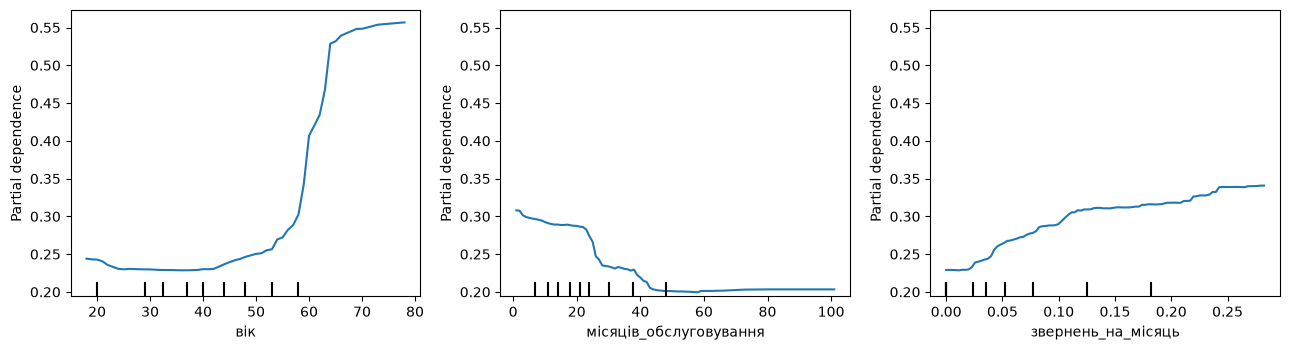

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# три найважливіші числові ознаки за перестановочною важливістю, без пропусків
num_no_nan = [c for c in perm_imp.index
              if str(FINAL_X[c].dtype) != 'category' and FINAL_X[c].nunique() > 2
              and Xte[c].notna().all()]
top3 = num_no_nan[:3]
print('ознаки для PDP:', top3)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
PartialDependenceDisplay.from_estimator(model, Xte, features=top3, kind='average', ax=ax)
plt.tight_layout(); plt.show()

**Висновок до завдання 10.1.** `вік`: ризик майже сталий (≈ 0,23) до 45 років, далі різко зростає після 55 років до ≈ 0,55. `місяців_обслуговування`: ризик найвищий у нових клієнтів (≈ 0,31) і спадає до ≈ 0,20 після 45 місяців. `звернень_на_місяць`: ризик плавно зростає від ≈ 0,23 до ≈ 0,34 зі збільшенням частоти звернень.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

,argmin,argmax,розмах,точок
вік,12.0,29.0,0.236,30.0
швидкість_тарифу_Мбіт,1.0,8.0,0.167,9.0
звернень_на_місяць,1.0,29.0,0.111,30.0
річний_платіж,2.0,29.0,0.105,30.0
місяців_обслуговування,29.0,0.0,0.103,30.0
дата_підключення,20.0,0.0,0.044,30.0
скоринг_партнера,13.0,0.0,0.043,30.0
кількість_звернень_у_підтримку,0.0,4.0,0.042,6.0


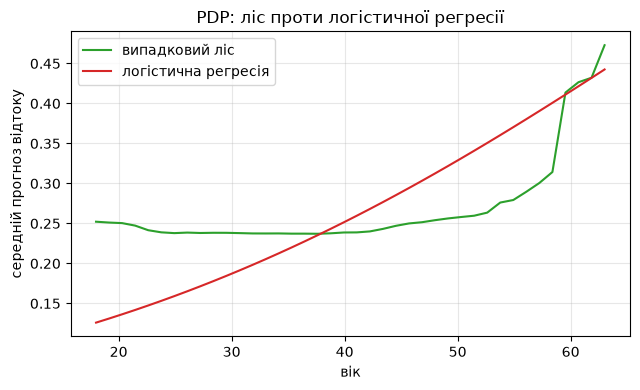

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# кандидати: PDP лісу для всіх числових ознак без пропусків, шукаємо немонотонну (є мінімум/максимум усередині)
cands = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category'
         and FINAL_X[c].nunique() > 5 and FINAL_X[c].notna().all()]
shape = {}
for c in cands:
    pd_ = partial_dependence(model, FINAL_X, [c], kind='average', grid_resolution=30)
    v = pd_['average'][0]
    shape[c] = (np.argmin(v), np.argmax(v), v.max() - v.min(), len(v))
display(pd.DataFrame(shape, index=['argmin', 'argmax', 'розмах', 'точок']).T
        .sort_values('розмах', ascending=False).head(8).round(3))

# логістична регресія на тих самих даних
lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(6.5, 4))
for nm, m_, col in [('випадковий ліс', model, 'tab:green'), ('логістична регресія', lr_model, 'tab:red')]:
    p = partial_dependence(m_, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
    ax.plot(p['grid_values'][0], p['average'][0], label=nm, color=col)
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній прогноз відтоку')
ax.set_title('PDP: ліс проти логістичної регресії'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [39]:
NONLINEAR_MEANING = 'ризик відтоку немонотонний за віком: у найстарших (понад 55 років) він різко зростає (46,5 % у групі 55–60 і 70,8 % понад 60 за сирими даними), найнижчий у віці близько 30–40 років (19,5 % у групі 30–35), а наймолодші клієнти (до 25 років) знову ризикованіші (25,7 %).'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'квадрат відхилення віку від точки мінімуму ризику: (вік − 35,5)², тоді лінійна модель отримує U-подібну залежність'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик відтоку немонотонний за віком: у найстарших (понад 55 років) він різко зростає (46,5 % у групі 55–60 і 70,8 % понад 60 за сирими даними), найнижчий у віці близько 30–40 років (19,5 % у групі 30–35), а наймолодші клієнти (до 25 років) знову ризикованіші (25,7 %).
квадрат відхилення віку від точки мінімуму ризику: (вік − 35,5)², тоді лінійна модель отримує U-подібну залежність


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# 1) значення, при якому ризик мінімальний (за PDP лісу)
p = partial_dependence(model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=60)
x_min = float(p['grid_values'][0][np.argmin(p['average'][0])])
print('мінімум ризику при %s ≈ %.1f' % (NONLINEAR_FEATURE, x_min))

# 2) нова ознака: квадрат відхилення від цього значення
X6 = X5.copy()
X6['відхилення_квадрат'] = (X6[NONLINEAR_FEATURE] - x_min) ** 2

# 3) парне порівняння логістичної регресії без неї і з нею
auc6 = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
auc5_ = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m6, h6 = paired(auc5_, auc6)
print('без ознаки: AUC %.4f;   з ознакою: AUC %.4f' % (auc5_.mean(), auc6.mean()))
print('приріст: %+0.4f ± %.4f   %s' % (m6, h6, 'значуще' if abs(m6) > h6 else 'у межах шуму'))

мінімум ризику при вік ≈ 35.5


без ознаки: AUC 0.8318;   з ознакою: AUC 0.8548
приріст: +0.0230 ± 0.0138   значуще


In [41]:
QUAD_GAIN = float(m6)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0230


**Висновок до завдання 10.2.** Ліс бачить, що вік має мінімум ризику біля 35 років і зростання після 55; логістична регресія може лише монотонно зростати. Додавання `(вік − 35,5)²` підвищило AUC лінійної моделі на +0,0230 ± 0,0138, тобто приріст значущий.

### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

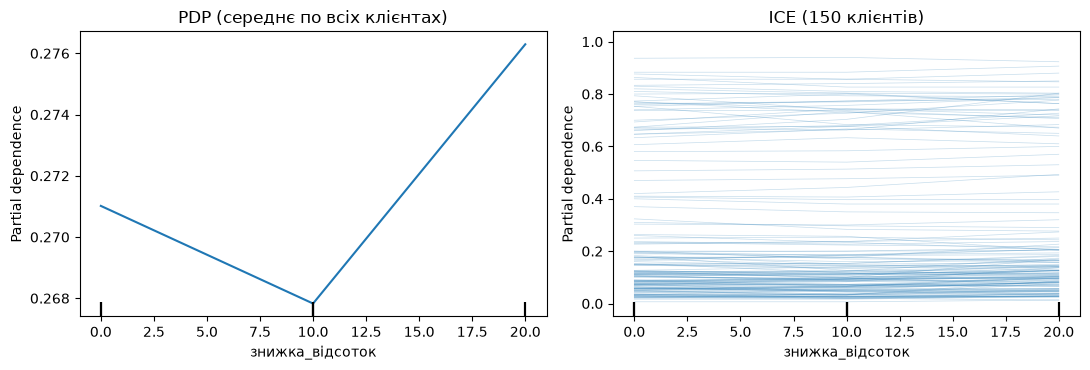

ICE: зростає 40 %, спадає 28 % клієнтів; PDP-різниця 20 % проти 0 %: +0.005


In [42]:
# пункт 1: PDP та ICE для 'знижка_відсоток' на повній матриці
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
ax[0].set_title('PDP (середнє по всіх клієнтах)')
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='individual',
                                        subsample=150, random_state=SEED, ax=ax[1],
                                        ice_lines_kw={'alpha': 0.25, 'color': 'tab:blue'})
ax[1].set_title('ICE (150 клієнтів)')
plt.tight_layout(); plt.show()

# скільки кривих зростає і скільки спадає від 0 до 20 %
ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
delta = ice[:, -1] - ice[:, 0]
print('ICE: зростає %.0f %%, спадає %.0f %% клієнтів; PDP-різниця 20 %% проти 0 %%: %+.3f'
      % ((delta > 0.01).mean() * 100, (delta < -0.01).mean() * 100,
         ice[:, -1].mean() - ice[:, 0].mean()))

стаж ≤ 24 міс. (n=719) [0.322 0.323 0.338]


стаж > 24 міс. (n=481) [0.195 0.185 0.184]


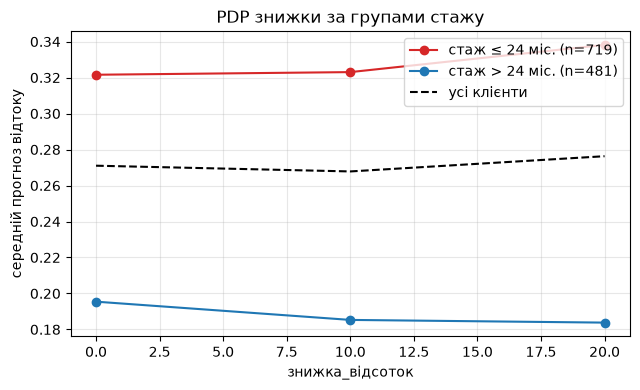

In [43]:
# пункт 3: PDP окремо за стажем
mask_new = (FINAL_X['місяців_обслуговування'] <= 24).values
fig, ax = plt.subplots(figsize=(6.5, 4))
for nm, mk, col in [('стаж ≤ 24 міс. (n=%d)' % mask_new.sum(), mask_new, 'tab:red'),
                    ('стаж > 24 міс. (n=%d)' % (~mask_new).sum(), ~mask_new, 'tab:blue')]:
    p = partial_dependence(model, FINAL_X[mk], ['знижка_відсоток'], kind='average')
    ax.plot(p['grid_values'][0], p['average'][0], 'o-', label=nm, color=col)
    print(nm, np.round(p['average'][0], 3))
p_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
ax.plot(p_all['grid_values'][0], p_all['average'][0], 'k--', label='усі клієнти')
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середній прогноз відтоку')
ax.set_title('PDP знижки за групами стажу'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
grp = np.where(raw['місяців_обслуговування'] <= 24, 'стаж ≤ 24', 'стаж > 24')
tab = raw.groupby([grp, 'знижка_відсоток'])[TARGET].agg(['mean', 'size']).round(3)
tab.columns = ['частка відтоку', 'клієнтів']
display(tab)
display(raw.groupby([grp, 'знижка_відсоток'])[TARGET].mean().unstack().round(3))

частка відтоку  клієнтів
          знижка_відсоток                          
стаж > 24 0                         0.253       166
          10                        0.128       187
          20                        0.039       128
стаж ≤ 24 0                         0.324       306
          10                        0.332       217
          20                        0.434       196

знижка_відсоток,0,10,20
стаж > 24,0.253,0.128,0.039
стаж ≤ 24,0.324,0.332,0.434


In [45]:
INTERACTION_FOUND = 'знижка діє протилежно в двох групах: у клієнтів зі стажем до 24 місяців частка відтоку зростає зі знижкою (32,4 % → 33,2 % → 43,4 % при знижці 0 / 10 / 20 %), а у клієнтів зі стажем понад 24 місяці різко падає (25,3 % → 12,8 % → 3,9 %). У PDP по всій вибірці крива майже пласка (+0,005), ICE показує розбіжність: у 40 % клієнтів прогноз зростає зі знижкою, у 28 % спадає. Ліс відтворює напрям, але ослаблено (стаж > 24: 0,195 → 0,184; стаж ≤ 24: 0,322 → 0,338), тож сирі дані показують ефект значно сильніший.'     # що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'пропонувати знижку лише клієнтам зі стажем понад 24 місяці, де вона корелює з істотним зниженням відтоку; для нових клієнтів знижка не пов’язана зі зниженням відтоку (відтік навіть вищий), тому для них потрібні інші заходи. Причинність потребує перевірки (наприклад, A/B-тестом): знижку, імовірно, отримують клієнти з різною історією.'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

знижка діє протилежно в двох групах: у клієнтів зі стажем до 24 місяців частка відтоку зростає зі знижкою (32,4 % → 33,2 % → 43,4 % при знижці 0 / 10 / 20 %), а у клієнтів зі стажем понад 24 місяці різко падає (25,3 % → 12,8 % → 3,9 %). У PDP по всій вибірці крива майже пласка (+0,005), ICE показує розбіжність: у 40 % клієнтів прогноз зростає зі знижкою, у 28 % спадає. Ліс відтворює напрям, але ослаблено (стаж > 24: 0,195 → 0,184; стаж ≤ 24: 0,322 → 0,338), тож сирі дані показують ефект значно сильніший.
пропонувати знижку лише клієнтам зі стажем понад 24 місяці, де вона корелює з істотним зниженням відтоку; для нових клієнтів знижка не пов’язана зі зниженням відтоку (відтік навіть вищий), тому для них потрібні інші заходи. Причинність потребує перевірки (наприклад, A/B-тестом): знижку, імовірно, отримують клієнти з різною історією.


**Висновок до завдання 10.3.** Крива PDP по всій вибірці майже пласка, але це результат взаємного погашення двох протилежних ефектів: знижка корелює зі зменшенням відтоку у стажевих клієнтів і зі зростанням у нових. Емпіричні частки в сирих даних підтверджують напрям, хоча модель ослабила його.

> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 93)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

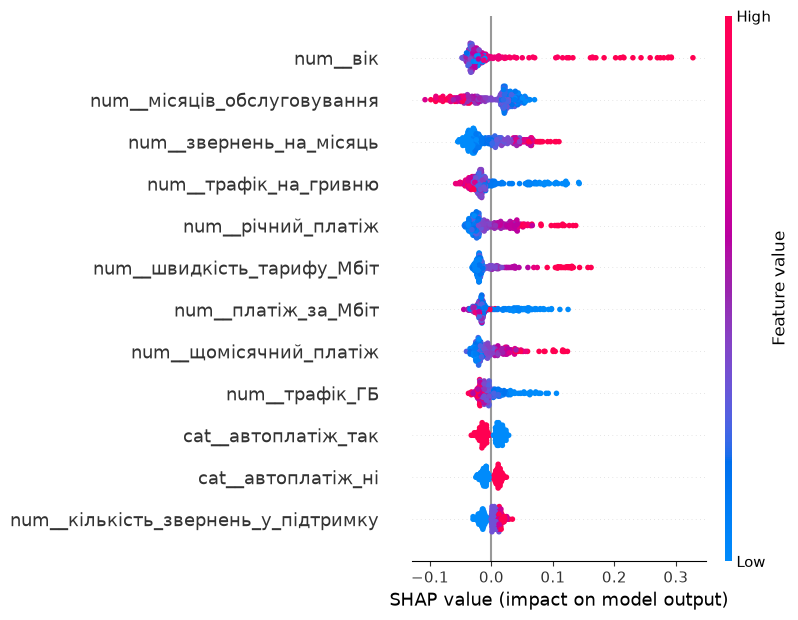

In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
proba = model.predict_proba(Xte)[:SAMPLE, 1]
idx = int(np.argmax(proba))
print('ризик клієнта: %.3f' % proba[idx])

base_value = float(np.ravel(expl.expected_value)[-1])
contrib = pd.Series(sv1[idx], index=feat_names)
# значення ознак клієнта (до перетворення)
row_raw = Xte.iloc[idx]
top_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
print('базовий рівень %.3f + сума внесків %.3f = %.3f' % (base_value, contrib.sum(), base_value + contrib.sum()))
out = []
for n_, v_ in top_c.items():
    o = origin(n_)
    out.append({'ознака': n_, 'вихідна ознака': o, 'значення у клієнта': row_raw[o], 'внесок': round(v_, 4)})
display(pd.DataFrame(out))
# внески, згруповані за вихідними ознаками (дамі-стовпці та дублікати разом)
by_feat = contrib.groupby(origin).sum()
display(by_feat.reindex(by_feat.abs().sort_values(ascending=False).index).head(8).round(4).to_frame('сумарний внесок'))
display(row_raw.to_frame('значення').T.round(2))
# для порівняння: типові значення в навчальній вибірці
display(Xtr[[o['вихідна ознака'] for o in out]].describe().loc[['25%', '50%', '75%']].round(2)
        if all(str(Xtr[o['вихідна ознака']].dtype) != 'category' for o in out) else '')

ризик клієнта: 0.893
базовий рівень 0.273 + сума внесків 0.620 = 0.893


,ознака,вихідна ознака,значення у клієнта,внесок
0,num__швидкість_тарифу_Мбіт,швидкість_тарифу_Мбіт,1000.00,0.1333
1,num__річний_платіж,річний_платіж,7160.40,0.1031
2,num__щомісячний_платіж,щомісячний_платіж,600.26,0.0872


,сумарний внесок
швидкість_тарифу_Мбіт,0.1333
річний_платіж,0.1031
щомісячний_платіж,0.0872
трафік_на_гривню,0.0812
платіж_за_Мбіт,0.0722
звернень_на_місяць,0.0654
місяців_обслуговування,0.0598
автоплатіж,-0.0158


,вік,стать,місто,тариф,тип_підключення,спосіб_оплати,автоплатіж,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,номер_договору_серія,скоринг_партнера,дата_підключення,платіж_за_Мбіт,звернень_на_місяць,трафік_на_гривню,новачок,аварії_без_звернень
значення,43.0,ж,львів,оптимальний,оптика,картка,так,2.0,9.0,1000.0,600.26,10.0,124.7,2.0,1.0,6.7,7160.4,ном-035,563.604,1717.0,0.60026,0.2,0.207743,0.0,0.0


,швидкість_тарифу_Мбіт,річний_платіж,щомісячний_платіж
25%,100.0,3091.15,256.89
50%,200.0,3680.90,307.92
75%,400.0,4382.00,364.69


In [49]:
EXPLANATION_FOR_MANAGER = 'Клієнта визначено як дуже ризикованого (ймовірність відходу 89 % за середніх 27 %). Головна причина — тариф: клієнт підключений на найшвидшому тарифі (1 Гбіт/с) і платить близько 600 грн на місяць, удвічі більше за типового абонента (≈ 300 грн); швидкість і вартість разом (річна й щомісячна плата — це одна й та сама величина) додають близько 32 відсоткових пунктів ризику. Далі за значущістю: клієнт мало користується трафіком відносно своєї плати (≈ 125 ГБ при 600 грн), що додає близько 8 пунктів, і часто звертається в підтримку (2 звернення за 9 місяців), що додає близько 7 пунктів.'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнта визначено як дуже ризикованого (ймовірність відходу 89 % за середніх 27 %). Головна причина — тариф: клієнт підключений на найшвидшому тарифі (1 Гбіт/с) і платить близько 600 грн на місяць, удвічі більше за типового абонента (≈ 300 грн); швидкість і вартість разом (річна й щомісячна плата — це одна й та сама величина) додають близько 32 відсоткових пунктів ризику. Далі за значущістю: клієнт мало користується трафіком відносно своєї плати (≈ 125 ГБ при 600 грн), що додає близько 8 пунктів, і часто звертається в підтримку (2 звернення за 9 місяців), що додає близько 7 пунктів.


**Висновок до завдання 11.** У beeswarm видно, що вік діє несиметрично: високі значення дають великі додатні внески (до +0,3), а низькі лише невеликі від’ємні; для `місяців_обслуговування` напрям протилежний (мала величина збільшує ризик). Для більшості клієнтів напрям внеску однаковий, але розкид у віку показує, що вплив залежить від групи.

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = 'вік має найбільший внесок за Шеплі (до +0,3 для найстарших клієнтів), але змінити його неможливо; крім того, це лише маркер групи (пенсіонери, інші потреби, інші способи оплати), а не причина: «модель користується віком» не означає «вік спричиняє відтік», і втручання тут неможливе.'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — вік має найбільший внесок за Шеплі (до +0,3 для найстарших клієнтів), але змінити його неможливо; крім того, це лише маркер групи (пенсіонери, інші потреби, інші способи оплати), а не причина: «модель користується віком» не означає «вік спричиняє відтік», і втручання тут неможливе.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'Річний і щомісячний платіж — це та сама інформація, тому внесок за Шеплі розкладається між двома колонками (обидві входять у топ-10, поряд із похідними «платіж_за_Мбіт» і «трафік_на_гривню»). Кожна окрема стовпчикова діаграма вказує на помірний внесок, хоча сумарно вартість тарифу — один із головних чинників. Висновок «вартість не критична, бо кожна колонка має скромний внесок» хибний; внески пов’язаних ознак слід підсумовувати.'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Річний і щомісячний платіж — це та сама інформація, тому внесок за Шеплі розкладається між двома колонками (обидві входять у топ-10, поряд із похідними «платіж_за_Мбіт» і «трафік_на_гривню»). Кожна окрема стовпчикова діаграма вказує на помірний внесок, хоча сумарно вартість тарифу — один із головних чинників. Висновок «вартість не критична, бо кожна колонка має скромний внесок» хибний; внески пов’язаних ознак слід підсумовувати.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
proba_te = model.predict_proba(Xte)[:, 1]
order = np.argsort(-proba_te)[:TOP_N]
top_rate = float(yte.iloc[order].mean())
base_rate = float(yte.mean())
lift = top_rate / base_rate
print('у перевірковій частині %d клієнтів, відтік %.3f (≈ %.0f з 100 навмання)' % (len(yte), base_rate, base_rate * TOP_N))
print('серед топ-%d за ризиком пішло %d (%.1f %%)' % (TOP_N, yte.iloc[order].sum(), top_rate * 100))
print('lift = %.2f' % lift)
print('AUC на відкладеній частині: %.3f' % auc_hold)

у перевірковій частині 360 клієнтів, відтік 0.272 (≈ 27 з 100 навмання)
серед топ-100 за ризиком пішло 59 (59.0 %)
lift = 2.17
AUC на відкладеній частині: 0.796


In [54]:
LIFT_MEANING = 'Серед 100 клієнтів із найвищим ризиком відходить 59 (59 %) проти 27,2 % у вибірці, тобто обдзвін за списком результативніший у 2,17 раза, ніж випадковий вибір.'
assert LIFT_MEANING
print(LIFT_MEANING)

Серед 100 клієнтів із найвищим ризиком відходить 59 (59 %) проти 27,2 % у вибірці, тобто обдзвін за списком результативніший у 2,17 раза, ніж випадковий вибір.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_04.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''

1. Обрано метрику AUC: частка відтоку 27,25 %, тому модель «ніхто не піде» мала б точність 72,75 %
   за нульової користі. AUC не залежить від порогу й оцінює якість ранжування клієнтів за ризиком, а саме
   за ним відділ утримання добиратиме, кому телефонувати. Схема: стратифікована 5-кратна, 4 повтори.

2. Викинуто: id_клієнта (ідентифікатор, з’являється при реєстрації, нічого не пояснює);
   сума_повернення_депозиту (повертається при закритті договору, тобто після розриву);
   код_причини_закриття (вказується в момент розірвання); оцінка_ризику_менеджером (менеджер ставить її,
   уже знаючи про намір клієнта піти: при оцінці 1 пішли 0 %, при 5 пішли 100 %); філія (підозрювана
   за артефактом збору). Детектор із 5.1 не знайшов оцінку менеджера: поле заповнене в усіх рядках,
   тому показник заповненості 0,5; витік міститься у значеннях, а не в пропусках.

3. Чесне число: AUC 0,834 ± 0,031. Драбина: 0,993 (усе підряд) → 0,972 (мінус цільовий витік) →
   0,846 (мінус оцінка менеджера) → 0,834 (мінус філія). Розкид ±0,031 у 8 разів більший за різницю
   0,004, тож такі моделі неможливо відрізнити: різниця в межах шуму (поправка Надо–Бенжіо дає
   довірчі інтервали ±0,027 і ±0,020).

4. Різкого артефакту збору немає: за кварталами підключення відтік коливається 20–32 % без
   сходинки; філії різняться від 17,6 % до 39,4 %. Чесними ознаками філії «Центр»+«Захід» вгадуються з
   AUC 0,692 (помірно: у них більше оптики, 86 % проти 70 %; середня швидкість тарифу вища, 354 проти 284 Мбіт, але медіана однакова, 200 Мбіт). Модель відтоку, навчену на цих
   філіях, не можна вважати переносною на іншу філію без перевірки; стовпець філії викинуто.

5. Нові ознаки: −0,0023 ± 0,0055 AUC, +0 с. Складніша модель: ліс −0,0042 ± 0,0266 (+3,7 с на 100
   навчань), бустинг −0,0021 ± 0,0204 (+5,3 с). Обидва приросту в межах шуму; єдиний значущий
   приріст дала ознака з PDP (квадрат відхилення віку: +0,0230 ± 0,0138 для логістичної регресії).

6. Вбудована важливість помилково назвала важливою номер_договору_серія (0,099 — 2-ге місце; перестановочна
   0,0017). Це ідентифікатор із 55 значень: дерево отримує багато можливих порогів і майже завжди
   знаходить розбиття, що трохи зменшує неоднорідність навіть без зв’язку з ціллю.

7. Для пари щомісячний_платіж / річний_платіж (r = 0,999) перестановочна важливість у повній моделі
   була +0,0074 і +0,0078, а після вилучення другої колонки щомісячний_платіж отримав +0,0168 (≈ сума
   двох). Це не вада методу: він правильно відповідає, що без однієї колонки модель не погіршиться, бо
   інформацію дублює інша. Вада в інтерпретації «важливість майже нуль, отже ознаку можна викинути».

8. Немонотонний вплив має вік (мінімум ризику ≈ 35,5 року; зростання після 55 років, а також
   трохи вищий ризик до 25 років). Логістична регресія без втручання цього не бачить: її PDP зростає
   монотонно (≈ 0,13 → 0,44). Квадрат відхилення віку дав приріст AUC +0,0230 ± 0,0138.

9. PDP знижки по всій вибірці майже плаский (+0,005 між 0 і 20 %), хоча за стажем ефект протилежний:
   до 24 місяців відтік зростає (32,4 → 43,4 %), понад 24 — падає (25,3 → 3,9 %). ICE показав, що в 40 %
   клієнтів прогноз зростає, у 28 % падає; PDP по підгрупах підтвердив різні напрями.

10. Вік: великий внесок за Шеплі (до +0,3), але змінити його неможливо, а сам він лише маркер групи.
    Значення Шеплі показують, як модель користується ознакою, а не що станеться при її зміні: причинний
    висновок потребує експерименту, якого в даних немає.

11. Обдзвін 100 клієнтів із найвищим ризиком дає 59 % реальних відтоків проти 27,2 % випадково,
    lift = 2,17. Застереження: оцінка зроблена на одній відкладеній частині з 360 клієнтів (AUC 0,796
    проти чесних 0,834 у крос-валідації), тому lift має широкий розкид; крім того, модель не каже, чи
    допоможе знижка: для клієнтів зі стажем до 24 місяців знижка корелює з вищим відтоком.

Декларація про використання ШІ: у роботі використано ШІ-асистента Claude Code. Він склав і виконав код
комірок, запропонував формулювання відповідей і звіту. Самостійно (за виводами комірок) перевірено:
відсутність помилок при виконанні згори вниз, коректність виявлених витоків (за частками відтоку по
значеннях оцінки менеджера та заповненості полів), числа в звіті (звірені з виводами) і висновки
щодо PDP, ICE та значень Шеплі (звірені з сирими таблицями).

'''
print(REPORT)



1. Обрано метрику AUC: частка відтоку 27,25 %, тому модель «ніхто не піде» мала б точність 72,75 %
   за нульової користі. AUC не залежить від порогу й оцінює якість ранжування клієнтів за ризиком, а саме
   за ним відділ утримання добиратиме, кому телефонувати. Схема: стратифікована 5-кратна, 4 повтори.

2. Викинуто: id_клієнта (ідентифікатор, з’являється при реєстрації, нічого не пояснює);
   сума_повернення_депозиту (повертається при закритті договору, тобто після розриву);
   код_причини_закриття (вказується в момент розірвання); оцінка_ризику_менеджером (менеджер ставить її,
   уже знаючи про намір клієнта піти: при оцінці 1 пішли 0 %, при 5 пішли 100 %); філія (підозрювана
   за артефактом збору). Детектор із 5.1 не знайшов оцінку менеджера: поле заповнене в усіх рядках,
   тому показник заповненості 0,5; витік міститься у значеннях, а не в пропусках.

3. Чесне число: AUC 0,834 ± 0,031. Драбина: 0,993 (усе підряд) → 0,972 (мінус цільовий витік) →
   0,846 (мінус оцінка менеджер

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.